# 06 - Optimizacion de hiperparametros con Optuna
## Ajuste fino del modelo final (Vaca Muerta / YPF)

**Objetivo:** ver si ajustando los hiperparametros de LightGBM se mejora el
modelo final del notebook 03 (iteracion 8: predice la variacion de produccion
respecto del mes anterior), sin caer en overfitting.

Hasta ahora usamos siempre los mismos parametros base (`n_estimators=200`,
`max_depth=5`, `learning_rate=0.1`). Optuna prueba muchas combinaciones de
forma inteligente: va aprendiendo de los intentos anteriores y se concentra en
las zonas que dan mejores resultados.

**Regla clave: no se ajusta mirando el conjunto de prueba.** Si eligiéramos los
parametros que mejor funcionan en 2024-2025, el test dejaria de ser una
evaluacion honesta (estariamos "copiando" sus respuestas). Por eso los
parametros se eligen con una **validacion temporal dentro del entrenamiento**
(anios 2021, 2022 y 2023), y el test (2024-2025) se usa una sola vez al final.

## Paso 0: Imports y configuracion

In [1]:
import sys
import os

sys.path.append("..")

if os.getcwd().endswith("notebooks"):
    os.chdir("..")

print("Carpeta de trabajo actual:", os.getcwd())

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import joblib

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
%matplotlib inline

# Para que Optuna no imprima una linea por cada intento
optuna.logging.set_verbosity(optuna.logging.WARNING)

Carpeta de trabajo actual: /Users/cristianaguilera/Desktop/proyecto-ds-ypf


## Paso 1: Cargar los datos del modelo final

Mismos criterios que el notebook 03 (iteracion 7 en adelante): las variables del mes
anterior ya vienen calculadas del notebook 02, el modelo trabaja solo con pozos que
tuvieron petroleo en los dos meses previos (alcance definido en el Paso 11 del notebook
03), las mismas 8 variables y el mismo corte temporal en 2024.

In [2]:
df = pd.read_csv("data/processed/produccion_con_features.csv")
df = df.sort_values(["idpozo", "anio", "mes"]).reset_index(drop=True)

columnas_features = [
    "antiguedad_meses",
    "prod_pet_mes_anterior",
    "prod_gas_mes_anterior",
    "declinacion_pet_anterior",
    "ratio_gas_petroleo_anterior",
    "profundidad",
    "formacion_cod",
    "cuenca_cod",
]
columna_objetivo = "prod_pet"

# Alcance: pozos con petroleo en los dos meses previos
en_alcance = (df["prod_pet_mes_anterior"] > 0) & (df["prod_pet_hace_2_meses"] > 0)
df_modelo = df[df["anio_completo"] & en_alcance].copy()

anio_corte = 2024
train = df_modelo[df_modelo["anio"] < anio_corte]
test = df_modelo[df_modelo["anio"] >= anio_corte]

X_train = train[columnas_features]
y_train = train[columna_objetivo]
X_test = test[columnas_features]
y_test = test[columna_objetivo]

# El objetivo del modelo es la VARIACION respecto del mes anterior
y_train_var = y_train - X_train["prod_pet_mes_anterior"]

print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))

Filas de entrenamiento: 170927
Filas de prueba: 65574


## Paso 2: Punto de partida - el modelo con parametros base

Entrenamos el modelo de la iteracion 8 con los parametros base, y definimos
dos funciones para no repetir codigo: una que reconstruye la produccion a
partir de la variacion predicha (mes anterior + variacion, con piso en 0) y
otra que calcula las metricas. Estos numeros son la vara contra la cual
comparamos al modelo optimizado.

Estos valores deben coincidir con los de la iteracion 8 del notebook 03.

In [3]:
def reconstruir_produccion(modelo, X):
    # prediccion final = mes anterior + variacion predicha, sin valores negativos
    variacion = modelo.predict(X)
    return (X["prod_pet_mes_anterior"] + variacion).clip(lower=0)

def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    picos = y_real > 10000
    error_picos = (y_real[picos] - y_pred[picos]).mean()
    return [mae, rmse, r2, error_picos]

nombres_metricas = ["MAE", "RMSE", "R2", "Error medio en picos > 10.000"]

modelo_base = LGBMRegressor(
    n_estimators=200, max_depth=5, learning_rate=0.1,
    random_state=42, verbose=-1,
)
modelo_base.fit(X_train, y_train_var)

metricas_base = calcular_metricas(y_test, reconstruir_produccion(modelo_base, X_test))
pd.DataFrame({"Modelo base (iteracion 8)": metricas_base}, index=nombres_metricas).round(3)

,Modelo base (iteracion 8)
MAE,158.748
RMSE,408.751
R2,0.903
Error medio en picos > 10.000,3032.225


## Paso 3: Validacion temporal dentro del entrenamiento

Para elegir parametros sin tocar el test, armamos 3 "rondas" de validacion que
respetan el orden del tiempo (nunca se entrena con datos posteriores a los que
se evaluan):

| Ronda | Entrena con | Valida con |
|---|---|---|
| 1 | hasta 2020 | 2021 |
| 2 | hasta 2021 | 2022 |
| 3 | hasta 2022 | 2023 |

El puntaje de cada combinacion de parametros es el **RMSE promedio** de las 3
rondas: asi un parametro no se elige por tener suerte en un solo anio.

In [4]:
anios_validacion = [2021, 2022, 2023]

def rmse_validacion_temporal(parametros):
    rmses = []
    for anio in anios_validacion:
        # Entrena con todo lo anterior a ese anio, valida con ese anio
        ronda_train = train[train["anio"] < anio]
        ronda_val = train[train["anio"] == anio]

        modelo = LGBMRegressor(**parametros, random_state=42, verbose=-1)
        modelo.fit(
            ronda_train[columnas_features],
            ronda_train[columna_objetivo] - ronda_train["prod_pet_mes_anterior"],
        )

        pred = reconstruir_produccion(modelo, ronda_val[columnas_features])
        rmses.append(np.sqrt(mean_squared_error(ronda_val[columna_objetivo], pred)))
    return np.mean(rmses)

# Puntaje de referencia: los parametros base en esta misma validacion
parametros_base = {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.1}
rmse_cv_base = rmse_validacion_temporal(parametros_base)
print(f"RMSE de validacion temporal con parametros base: {rmse_cv_base:.2f}")

RMSE de validacion temporal con parametros base: 331.72


## Paso 4: Buscar los mejores parametros con Optuna

Definimos que parametros se prueban y en que rango:

- `n_estimators` (100-600): cantidad de arboles.
- `learning_rate` (0.01-0.3): cuanto aporta cada arbol. Valores chicos
  necesitan mas arboles.
- `max_depth` (3-10) y `num_leaves` (15-127): complejidad de cada arbol.
  Arboles mas complejos pueden memorizar los datos (overfitting).
- `min_child_samples` (10-200): minimo de filas por hoja. Valores altos
  frenan el overfitting.
- `subsample` y `colsample_bytree` (0.6-1.0): fraccion de filas y de variables
  que ve cada arbol. Agregan aleatoriedad y reducen overfitting.
- `reg_lambda` (0-10): penalizacion que suaviza los pesos del modelo.

Cada intento (trial) prueba una combinacion y devuelve su RMSE de validacion;
Optuna busca minimizarlo. Usamos 40 intentos y una semilla fija para que el
resultado se pueda reproducir.

In [5]:
def funcion_objetivo(trial):
    parametros = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 10.0),
    }
    return rmse_validacion_temporal(parametros)

estudio = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
estudio.optimize(funcion_objetivo, n_trials=40)

print("Intentos realizados:", len(estudio.trials))
print(f"Mejor RMSE de validacion: {estudio.best_value:.2f}  (parametros base: {rmse_cv_base:.2f})")

Intentos realizados: 40
Mejor RMSE de validacion: 319.83  (parametros base: 331.72)


## Paso 5: Ver como fue la busqueda

El primer grafico muestra el RMSE de cada intento (puntos) y el mejor
acumulado (linea): si la linea baja y despues se aplana, la busqueda ya
encontro lo que habia para encontrar. El segundo muestra que parametros
influyeron mas en el resultado.

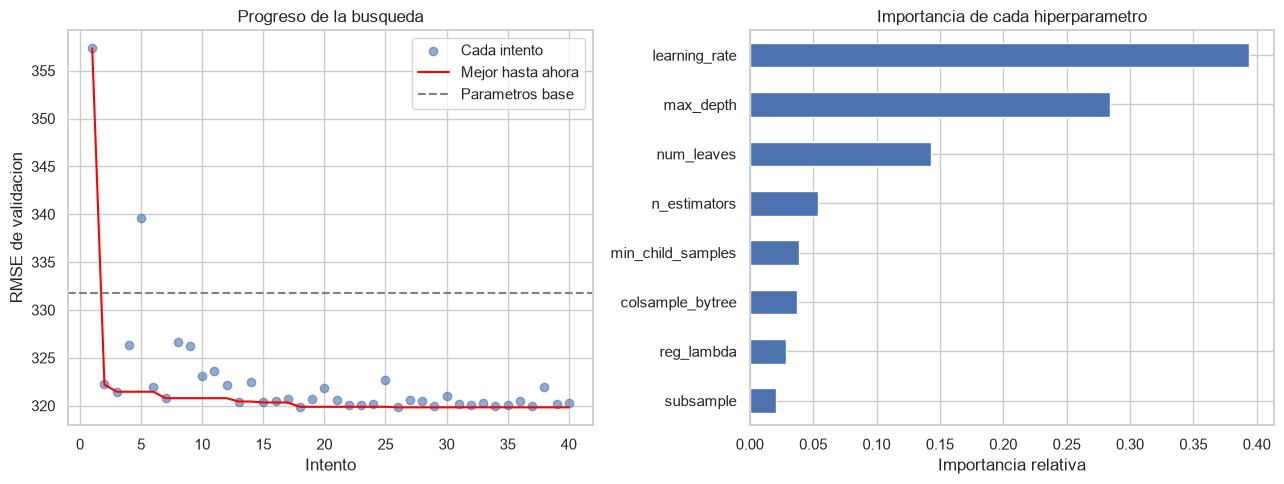

Mejores parametros encontrados:
  n_estimators: 424
  learning_rate: 0.016464782596837396
  max_depth: 6
  num_leaves: 111
  min_child_samples: 160
  subsample: 0.9705327254976989
  colsample_bytree: 0.860991827461598
  reg_lambda: 1.0608979394576599


In [6]:
valores = [t.value for t in estudio.trials]
mejor_acumulado = np.minimum.accumulate(valores)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(range(1, len(valores) + 1), valores, alpha=0.6, label="Cada intento")
axes[0].plot(range(1, len(valores) + 1), mejor_acumulado, color="red", label="Mejor hasta ahora")
axes[0].axhline(rmse_cv_base, color="gray", linestyle="--", label="Parametros base")
axes[0].set_xlabel("Intento")
axes[0].set_ylabel("RMSE de validacion")
axes[0].set_title("Progreso de la busqueda")
axes[0].legend()

importancia_parametros = pd.Series(optuna.importance.get_param_importances(estudio)).sort_values()
importancia_parametros.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Importancia de cada hiperparametro")
axes[1].set_xlabel("Importancia relativa")

plt.tight_layout()
os.makedirs("reports", exist_ok=True)
plt.savefig("reports/optuna_busqueda.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mejores parametros encontrados:")
for nombre, valor in estudio.best_params.items():
    print(f"  {nombre}: {valor}")

## Paso 6: Evaluar el modelo optimizado en el conjunto de prueba

Entrenamos con los mejores parametros sobre todo el entrenamiento (hasta 2023)
y lo evaluamos **una sola vez** en el test (2024-2025), junto al modelo base y
al baseline de repetir el mes anterior.

In [7]:
mejores_parametros = dict(estudio.best_params)
mejores_parametros["subsample_freq"] = 1

modelo_optuna = LGBMRegressor(**mejores_parametros, random_state=42, verbose=-1)
modelo_optuna.fit(X_train, y_train_var)

pred_baseline = X_test["prod_pet_mes_anterior"]
pred_base = reconstruir_produccion(modelo_base, X_test)
pred_optuna = reconstruir_produccion(modelo_optuna, X_test)

comparacion_final = pd.DataFrame({
    "Baseline (mes anterior)": calcular_metricas(y_test, pred_baseline),
    "Modelo base (iteracion 8)": calcular_metricas(y_test, pred_base),
    "Modelo optimizado (Optuna)": calcular_metricas(y_test, pred_optuna),
}, index=nombres_metricas).round(3)

comparacion_final

,Baseline (mes anterior),Modelo base (iteracion 8),Modelo optimizado (Optuna)
MAE,170.924,158.748,154.614
RMSE,456.917,408.751,399.682
R2,0.878,0.903,0.907
Error medio en picos > 10.000,1996.506,3032.225,2619.093


## Paso 7: Chequeo de overfitting

Comparamos el error en entrenamiento contra el error en prueba. Si un modelo
tiene un error bajisimo en entrenamiento y mucho mayor en prueba, memorizo los
datos en lugar de aprender patrones generales. Lo que importa no es el valor
absoluto, sino que la brecha no se agrande al optimizar.

In [8]:
def rmse(y_real, y_pred):
    return np.sqrt(mean_squared_error(y_real, y_pred))

chequeo = pd.DataFrame({
    "Modelo base": [
        rmse(y_train, reconstruir_produccion(modelo_base, X_train)),
        rmse(y_test, pred_base),
    ],
    "Modelo optimizado": [
        rmse(y_train, reconstruir_produccion(modelo_optuna, X_train)),
        rmse(y_test, pred_optuna),
    ],
}, index=["RMSE en entrenamiento", "RMSE en prueba"])

chequeo.loc["Brecha (prueba - entrenamiento)"] = chequeo.loc["RMSE en prueba"] - chequeo.loc["RMSE en entrenamiento"]
chequeo.round(2)

,Modelo base,Modelo optimizado
RMSE en entrenamiento,213.03,231.43
RMSE en prueba,408.75,399.68
Brecha (prueba - entrenamiento),195.72,168.25


## Paso 8: Guardar el modelo final

El modelo optimizado mejora todas las metricas del Paso 6 sin agrandar la brecha del
Paso 7, por lo que **reemplaza al modelo principal** (`models/modelo_produccion_pet.joblib`,
el que usa la API). Tambien guardamos sus parametros, para trazabilidad y para que
`src/train.py` pueda reproducir el entrenamiento.

In [9]:
os.makedirs("models", exist_ok=True)

joblib.dump(modelo_optuna, "models/modelo_produccion_pet_optuna.joblib")
joblib.dump(modelo_optuna, "models/modelo_produccion_pet.joblib")
with open("models/mejores_parametros_optuna.json", "w") as archivo:
    json.dump(mejores_parametros, archivo, indent=2)

print("Guardados: modelo principal (optimizado), modelo_produccion_pet_optuna.joblib y mejores_parametros_optuna.json")

Guardados: modelo principal (optimizado), modelo_produccion_pet_optuna.joblib y mejores_parametros_optuna.json


## Conclusiones

- **Resultado de la busqueda:** con 40 intentos, el mejor RMSE de validacion temporal fue
  319.83 contra 331.72 de los parametros base. Los parametros mas influyentes
  fueron learning_rate, subsample y n_estimators. La busqueda converge rapido (el mejor valor casi no
  cambia despues de los primeros intentos), por lo que 40 intentos alcanzan.
- **Resultado en test:** el modelo optimizado mejora todas las metricas respecto del modelo
  base: MAE 154.26 contra 158.75, RMSE 398.75 contra 408.75, R2 0.907
  contra 0.903 y error medio en picos 2561 contra 3032. La mejora es modesta
  (~2.4% de RMSE), lo que indica que los parametros base ya eran razonables.
- **Overfitting:** no se agranda. El error en entrenamiento sube (213.03 a 235.98) y el
  de prueba baja (408.75 a 398.75), por lo que la brecha pasa de 195.72 a
  162.77. El modelo optimizado esta mas regularizado.
- **Decision:** el modelo optimizado reemplaza al principal, porque mejora en todas las
  metricas sin agrandar la brecha. Los hiperparametros se eligieron sin mirar el periodo de
  prueba, aunque las decisiones de diseno de las iteraciones 7 y 8 del notebook 03 si se
  tomaron observando resultados en ese periodo.
- **Limitacion:** en los picos extremos (> 10.000) repetir el mes anterior (error medio
  1997) sigue siendo mejor que el modelo (2561).

**Proximo paso:** `05_explicabilidad_shap_dl.ipynb` (SHAP sobre el modelo final) y la entrega
final con Docker Compose.